In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from dataset.dataset import load_data
from softmax_CBM.dataset.dataset import load_data as load_data_softmax
from dataset.utils import *
import matplotlib.pyplot as plt

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("Device:", device, torch.cuda.get_device_name(0))
else:
    print("Device:", device)

Device: cuda:0 NVIDIA GeForce GTX 1650 Ti


In [3]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts



N_CONCEPT = 17
N_CLASSES = 52
val_loader = load_data("./dataset/playing_cards/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/playing_cards", return_orig=True)

concept_index_to_string = IndexToString("./dataset/playing_cards/attributes.txt")


"""
N_CONCEPT = 52
N_CLASSES = 1
val_loader = load_data("./dataset/three_card_poker/val.pkl", 16, dataset_root="./dataset/three_card_poker", has_class=False, return_orig=True)

concept_index_to_string = IndexToString("./dataset/three_card_poker/concepts.txt")
"""

XtoC = PlayingCardNet(num_classes=N_CONCEPT)
XtoC.load_state_dict(torch.load("./saves/XtoC_converted.pth"))
XtoC.to(device)
XtoC.eval()

print("model loaded")

model loaded


In [4]:
##### https://github.com/fhvilshoj/TorchLRP/blob/74253a1be05f0be0b7c535736023408670443b6e/examples/visualization.py#L60
def heatmap(X, cmap_name="seismic"):
	cmap = plt.cm.get_cmap(cmap_name)

	if X.shape[1] in [1, 3]:  # move channel index to end + convert to np array
		X = X.permute(0, 2, 3, 1).detach().cpu().numpy()
	if isinstance(X, torch.Tensor):  # convert tensor to np array
		X = X.detach().cpu().numpy()

	shape = X.shape
	tmp = X.sum(axis=-1) # Reduce channel axis

	tmp = project(tmp, output_range=(0, 255)).astype(int)
	tmp = cmap(tmp.flatten())[:, :3].T
	tmp = tmp.T

	shape = list(shape)
	shape[-1] = 3
	return tmp.reshape(shape).astype(np.float32)


def project(X, output_range=(0, 1)):
	absmax = np.abs(X).max(axis=tuple(range(1, len(X.shape))), keepdims=True)
	X /= absmax + (absmax == 0).astype(float)
	X = (X+1) / 2. # range [0, 1]
	X = output_range[0] + X * (output_range[1] - output_range[0]) # range [x, y]
	return X

In [5]:
XtoC = convert(XtoC).to(device)

print(XtoC)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Conv2d(256, 512, kernel_si

## Show predicted concepts and classification

In [17]:
transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean = [0.5, 0.5, 0.5], std = [2, 2, 2])
])

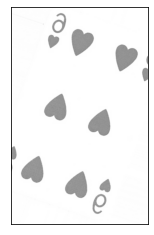

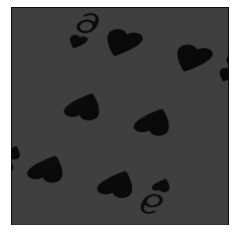

In [95]:
image = Image.open("temp/37750_edit12.jpg").convert('RGB')

plt.xticks([])
plt.yticks([])
plt.imshow(image)
plt.show()

image = transform(image)

plt.xticks([])
plt.yticks([])
plt.imshow(image.permute(1, 2, 0))
plt.show()

In [96]:
imageIn = image.to(device)
imageIn = imageIn.unsqueeze(0)
imageIn.requires_grad_(True)
imageIn.grad = None

# get model prediction and LRP map for classification
prediction = XtoC(imageIn)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

Predicted concepts: tensor([[    0.9806,     0.0008,     0.0002,     0.0000,     0.0001,     0.0001,
             0.0001,     0.0001,     0.0001,     0.0123,     0.0013,     0.0012,
             0.0004,     0.0002,     0.0003,     0.3978,     0.3999]],
       device='cuda:0', grad_fn=<SigmoidBackward0>)
id: 0, concept name: Ace, sig value: 0.9805582165718079


## Generate LRP saliency maps for concepts using a single rule

In [97]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 15:
        XtoC_model_1.append(m)
    elif idx < 29:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device)
XtoC_model_2.to(device)
XtoC_model_3.to(device)

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(256, 5

Ace


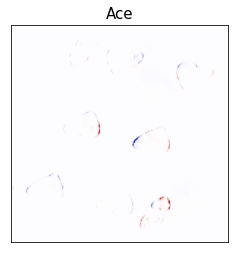

2


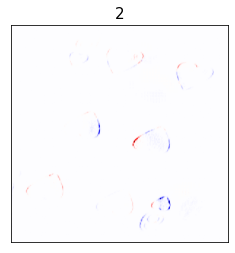

3


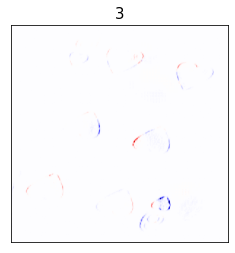

4


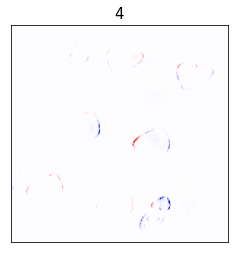

5


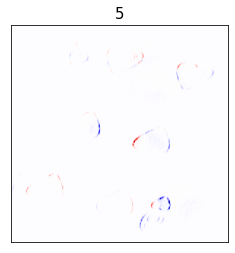

6


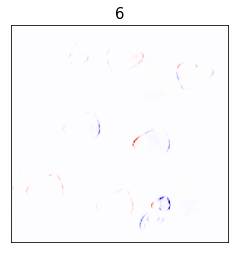

7


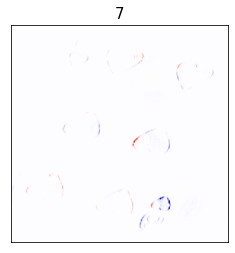

8


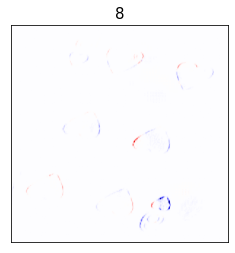

9


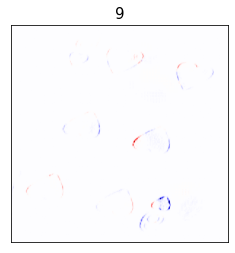

10


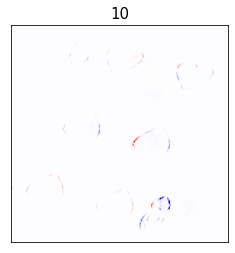

Jack


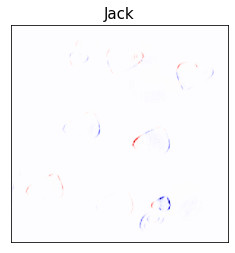

Queen


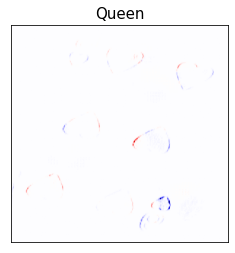

King


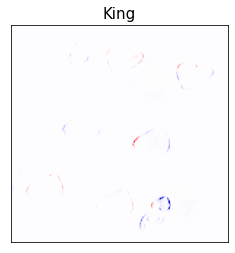

Hearts


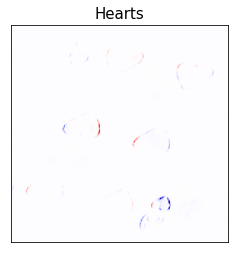

Diamonds


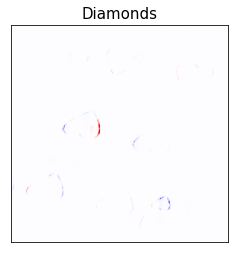

Clubs


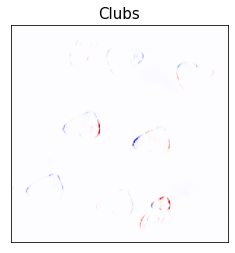

Spades


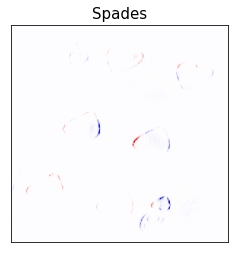

In [98]:
imageIn = image.to(device)
imageIn = imageIn.unsqueeze(0)
imageIn.requires_grad_(True)
imageIn.grad = None

output_1 = XtoC_model_1.forward(imageIn, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")
    
# get saliecy maps for top 5 concepts
pred_precent_concepts = []
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        pred_precent_concepts.append((idx, i.item()))

pred_precent_concepts = sorted(pred_precent_concepts, key=lambda x: -x[1])

for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        imageIn,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(concept_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close() 
